# 第二部分 · Matching 的条件起点

在正式实验的 Matching 任务中，证据积累的起点是否随形状条件变化？重点比较 Good-self 与 Bad-self 的组层 \(z\)。
用同一批留出试次比较共享起点与条件起点模型的预测表现。

## 1. 数据与试次划分

输入是第一部分的 [01_behavior.R](../../01_reproduction_2020/scripts/01_behavior.R) 导出的 `matching_hddm.csv`。使用 CPU DockerHDDM `hcp4715/hddm:1.0.1` 的 `python3` 内核。

`match` 是实际匹配状态，`val` 和 `id` 是形状的效价与身份。`stim` 是正确选项，`response` 是被试实际选择，两者均以 1 表示 Match、0 表示 Mismatch。RT 以秒计。HDDM 输入按原始数据的 `ACC = 0/1` 筛选，保留正确与错误试次。按被试和试次条件留出约 20% 的数据，评价同一批被试的新试次预测。

In [1]:
# 导入建模、数据处理和绘图所需的库。
from pathlib import Path

import hddm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 读取 Matching 试次表，定义形状条件和试次条件。
trials = hddm.load_csv("../../01_reproduction_2020/data/derived/matching_hddm.csv")
shape_columns = ["val", "id"]
trial_columns = ["match", *shape_columns]

# 从每位被试的各试次条件中留出约 20% 的试次，两套模型共用该划分。
heldout_index = trials.groupby(["subj_idx", *trial_columns]).sample(
    frac=0.2, random_state=2026
).index
training_trials = trials.drop(index=heldout_index).reset_index(drop=True)
heldout_trials = trials.loc[heldout_index].reset_index(drop=True)

# 制作样本量和各条件实际选择次数的表格。
display(pd.Series({
    "subjects": trials["subj_idx"].nunique(),
    "training_trials": len(training_trials),
    "heldout_trials": len(heldout_trials),
}, name="count"))
display(pd.crosstab(
    [trials[column] for column in trial_columns], trials["response"]
))

subjects              42
training_trials    19599
heldout_trials      4929
Name: count, dtype: int64

response                0     1
match    val  id               
match    Bad  Other   515  2552
              Self    561  2501
         Good Other   463  2618
              Self    262  2844
mismatch Bad  Other  2658   394
              Self   2525   530
         Good Other  2463   568
              Self   2492   582

### 1.1 Matching 的反应时与辨别力

按第一部分的 R 脚本汇总保留的全部 Matching 行为试次。反应时取正确匹配试次，辨别力 \(d'\) 由命中率和虚报率计算。彩色点为组均值，误差条为均值 ± 1.96 个标准误。[行为分析 R 脚本](../../01_reproduction_2020/scripts/01_behavior.R)

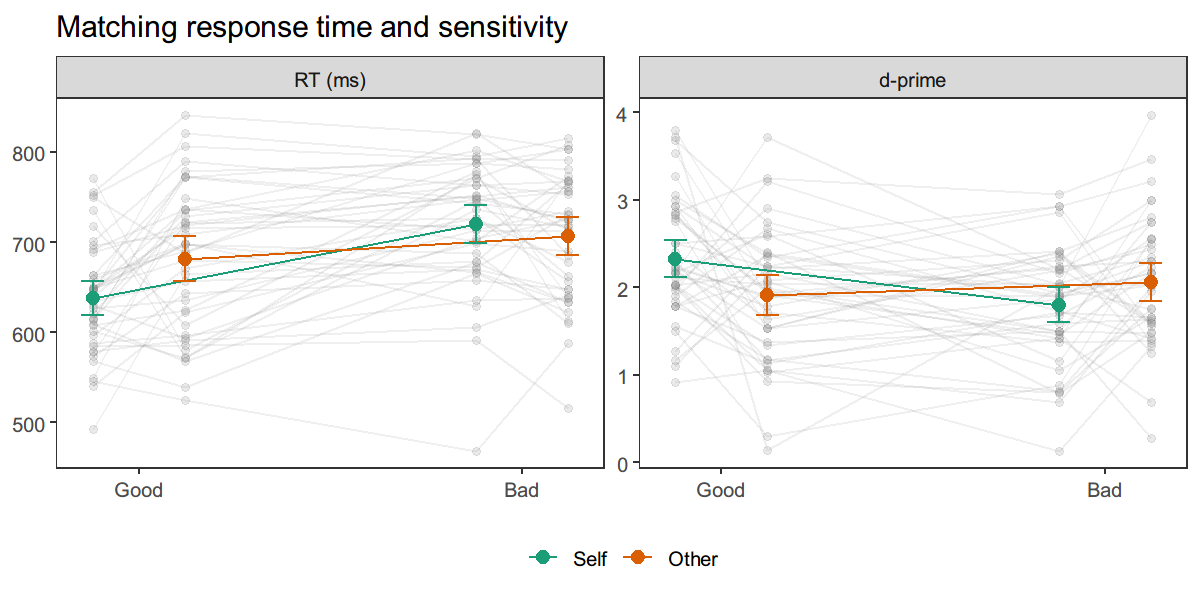

## 2. 模型与采样

证据在 0 和 \(a\) 之间从 \(az\) 开始累积。触及上边界时选 Match，触及下边界时选 Mismatch。有效漂移率为 \((2\,\mathrm{stim}-1)v\)，观察 RT 是触界时间加非决策时间 \(t\)。

| 模型 | \(v\) 与 \(t\) | \(a\) | \(z\) |
| --- | --- | --- | --- |
| M1 共享起点 | 按匹配状态 × 效价 × 身份估计 | 被试内共享 | 被试内共享 |
| M2 条件起点 | 按匹配状态 × 效价 × 身份估计 | 被试内共享 | 按效价 × 身份估计 |

两套模型沿用[第一部分 Matching 的设定](../../01_reproduction_2020/scripts/02_matching_hddm.ipynb)和 HDDM 1.0.1RC 的默认层级先验。Gamma 用均值和标准差表示，HalfNormal 括号内是尺度。异常反应混合权重固定为 0。

| 参数 | 组均值先验 | 被试层分布 | 被试层标准差先验 |
| --- | --- | --- | --- |
| \(v\) | Normal(2, SD 3) | Normal | HalfNormal(2) |
| \(t\) | Gamma(0.40, SD 0.20) | Gamma | HalfNormal(1) |
| \(a\) | Gamma(1.50, SD 0.75) | Gamma | HalfNormal(2) |
| \(\operatorname{logit}(z)\) | Normal(0, SD 0.50) | Normal | HalfNormal(0.05) |

每套模型运行四条独立链，每条采样 10,000 次，舍弃前 1,000 次。

In [2]:
# M1 · v 和 t 按试次条件估计，四个形状条件共用同一被试的 z。
def build_m1(data):
    return hddm.HDDMStimCoding(
        data,
        include=("v", "a", "t", "z"),
        stim_col="stim",
        split_param="v",
        drift_criterion=False,
        depends_on={"v": trial_columns, "t": trial_columns},
        p_outlier=0.0,
    )


# M2 · v 和 t 按试次条件估计，z 按形状条件估计。
def build_m2(data):
    return hddm.HDDMStimCoding(
        data,
        include=("v", "a", "t", "z"),
        stim_col="stim",
        split_param="v",
        drift_criterion=False,
        depends_on={
            "v": trial_columns,
            "t": trial_columns,
            "z": shape_columns,
        },
        p_outlier=0.0,
    )


# 指定四个形状条件的组层 z 节点和自我条件差值的名称。
condition_z_nodes = {
    "Good-self": "z(Self.Good)",
    "Bad-self": "z(Self.Bad)",
    "Good-other": "z(Other.Good)",
    "Bad-other": "z(Other.Bad)",
}
contrast_name = "Good-self - Bad-self"

In [3]:
# 设置链数、每链采样次数与预热次数。
n_chains = 4
n_samples = 10_000
burn_in = 1_000


def sample_chains(data, build_model, seed):
    # 为各链构造模型、初始化并采样。
    chains = []
    for chain_index in range(n_chains):
        np.random.seed(seed + chain_index)
        model = build_model(data)
        model.find_starting_values()
        model.sample(n_samples, burn=burn_in, progress_bar=False)
        chains.append(model)
    return chains

## 3. 生成恢复模拟数据

起点模拟改写自[邬思宇、潘晚坷与胡传鹏的生成代码](https://github.com/Chuan-Peng-Lab/ddm_stim_coding_posts/blob/468965c8d4c991bb7633f3f38257a6bac978bce5/1_Simulation/1_1_starting_point_bias/data_generation.py)（CC BY 4.0）。每位被试抽取一个 \(z_0\sim\operatorname{Normal}(0.50,0.05^2)\)。Good-self 的起点为 \(z_0+0.10\)，其余形状为 \(z_0\)。两类刺激分别生成，反应统一编码为 1=Match、0=Mismatch。

组均值沿用教程的设定 \(v=1.00\)、\(a=1.00\)、\(t=0.28\) 秒。三者的被试间标准差取自实证 M2 的后验中位数。每位被试抽一个 \(a\)，每个被试和试次条件抽 \(v,t\)。\(v\) 用正态分布，\(a,t\) 用 Gamma 分布。按每位被试在拟合数据中的各条件试次数生成。

In [4]:
# 定义组层真值和被试间标准差。
np.random.seed(2030)
group_means = {"v": 1.00, "a": 1.00, "t": 0.28}
subject_sd = {"v": 0.659, "a": 0.133, "t": 0.124, "z": 0.05}
true_z = {"Good-self": 0.60, "Bad-self": 0.50, "Good-other": 0.50, "Bad-other": 0.50}
simulated_trials = training_trials[["subj_idx", "stim", *trial_columns]].copy()


def draw_gamma(mean, sd):
    # 用均值和标准差定义 Gamma 分布。
    return np.random.gamma(shape=(mean / sd) ** 2, scale=sd**2 / mean)


# 为每位被试抽取基线起点和边界间距，按各条件的试次数生成选择与 RT。
for _, subject_rows in simulated_trials.groupby("subj_idx"):
    z_base = np.random.normal(0.50, subject_sd["z"])
    a = draw_gamma(group_means["a"], subject_sd["a"])

    for (stim, valence, identity), rows in subject_rows.groupby(["stim", *shape_columns]):
        shape = f"{valence}-{identity.lower()}"
        z = z_base + (true_z[shape] - 0.50)
        v = np.random.normal(group_means["v"], subject_sd["v"])
        t = draw_gamma(group_means["t"], subject_sd["t"])

        # 对不匹配刺激翻转生成器的起点，再把反应换回统一的 Match 编码。
        params = {"v": v, "a": a, "t": t, "z": z if stim == 1 else 1 - z}
        simulated, _ = hddm.generate.gen_rand_data(
            params=params, size=len(rows), subjs=1, subj_noise=0,
        )
        response = simulated["response"].to_numpy()
        simulated_trials.loc[rows.index, "response"] = response if stim == 1 else 1 - response
        simulated_trials.loc[rows.index, "rt"] = simulated["rt"].to_numpy()

## 4. 拟合与链诊断

用 M2 拟合模拟试次，在同一批实证训练试次上分别拟合 M1 和 M2。计算各随机参数的经典四链 \(\hat R\)，并叠画四条链的轨迹。M1 和 M2 展示 Good-self 匹配试次的组层 \(v\)、\(t\)，以及共享 \(a\) 和对应的 \(z\)。模拟恢复展示 \(v\)、\(t\)、\(\operatorname{logit}(z)\) 的被试间标准差及 Good-self 的 \(z\)。

In [5]:
# 用 M2 拟合恢复模拟试次。
recovery_chains = sample_chains(simulated_trials, build_m2, seed=2100)

# 在同一批拟合试次上分别估计 M1 和 M2。
model_chains = {
    "M1": sample_chains(training_trials, build_m1, seed=2200),
    "M2": sample_chains(training_trials, build_m2, seed=2300),
}

# 制作模拟恢复和实证模型的逐参数 R̂ 表，显示每次拟合的最大值。
diagnostic_chains = {"Recovery": recovery_chains, **model_chains}
rhat_table = pd.concat({
    name: pd.Series(hddm.analyze.gelman_rubin(chains), name="r_hat")
    for name, chains in diagnostic_chains.items()
}, names=["model", "parameter"]).to_frame()
display(rhat_table.groupby(level="model")["r_hat"].max().rename("max_r_hat").to_frame())

,max_r_hat
model,
M1,1.000593
M2,1.000673
Recovery,1.000833


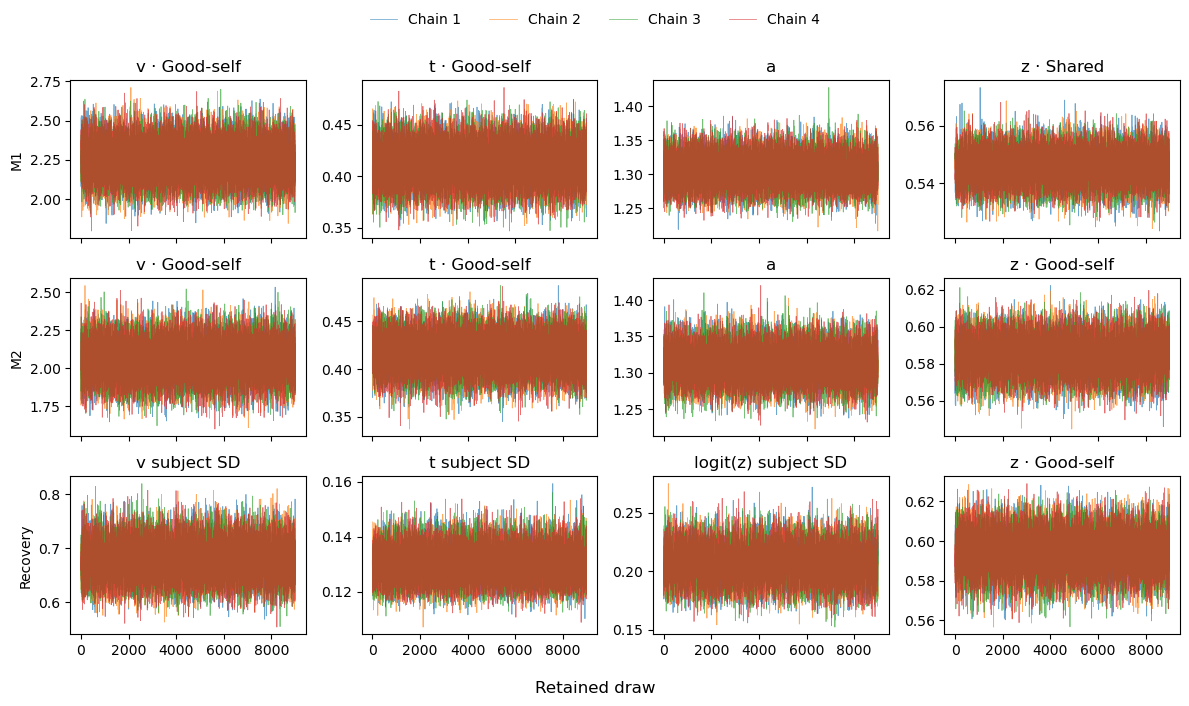

In [6]:
# 指定四链轨迹图的参数，M1 和 M2 使用相同的 v、t、a 面板。
matching_trace_nodes = [
    ("v · Good-self", "v(Self.match.Good)"),
    ("t · Good-self", "t(Self.match.Good)"),
    ("a", "a"),
]
trace_parameters = {
    "M1": [*matching_trace_nodes, ("z · Shared", "z")],
    "M2": [*matching_trace_nodes, ("z · Good-self", condition_z_nodes["Good-self"])],
    "Recovery": [
        ("v subject SD", "v_std"),
        ("t subject SD", "t_std"),
        ("logit(z) subject SD", "z_std"),
        ("z · Good-self", condition_z_nodes["Good-self"]),
    ],
}

# 绘制四链轨迹图，每行对应一次拟合。
trace_figure, axes = plt.subplots(3, 4, figsize=(12, 7), sharex=True)
for model_name, row in zip(trace_parameters, axes):
    row[0].set_ylabel(model_name)
    for ax, (title, node) in zip(row, trace_parameters[model_name]):
        for chain_id, chain in enumerate(diagnostic_chains[model_name], start=1):
            ax.plot(chain[node].trace(), lw=0.55, alpha=0.65, label=f"Chain {chain_id}")
        ax.set_title(title)

handles, labels = axes[0, 0].get_legend_handles_labels()
trace_figure.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
trace_figure.supxlabel("Retained draw")
trace_figure.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 5. 恢复结果与参数后验

### 5.1 起点恢复对照

在这一组模拟设置下，对照各条件的组层起点及 Good-self 减 Bad-self 差值的设定真值、后验均值和 95% 可信区间。

In [7]:
def group_draws(chains, nodes):
    # 合并各条链的组层参数抽样。
    return pd.concat([
        pd.DataFrame({label: chain[node].trace() for label, node in nodes.items()})
        for chain in chains
    ], ignore_index=True)


def summarize_draws(draws):
    # 制作后验均值和 95% 等尾可信区间表。
    interval = draws.quantile([0.025, 0.975])
    return pd.DataFrame({
        "mean": draws.mean(),
        "lower_95": interval.loc[0.025],
        "upper_95": interval.loc[0.975],
    })


# 提取模拟拟合的组层起点抽样。
recovery_draws = group_draws(recovery_chains, condition_z_nodes)

# 制作各条件 z 及 Good-self 减 Bad-self 的真值与后验对照表。
recovery_draws[contrast_name] = recovery_draws["Good-self"] - recovery_draws["Bad-self"]
recovery_summary = summarize_draws(recovery_draws)
recovery_summary["true_value"] = pd.Series({
    **true_z, contrast_name: true_z["Good-self"] - true_z["Bad-self"]
})
display(recovery_summary.round(3))

,mean,lower_95,upper_95,true_value
Good-self,0.595,0.576,0.613,0.6
Bad-self,0.495,0.477,0.514,0.5
Good-other,0.499,0.480,0.518,0.5
Bad-other,0.519,0.501,0.538,0.5
Good-self - Bad-self,0.099,0.073,0.125,0.1


### 5.2 实证起点后验

汇总 M1 的共享 \(z\)、M2 的四个条件 \(z\) 和 Good-self 减 Bad-self 的差值。对单个 \(z\) 以 \(0.5\) 为中性起点，对差值以 \(0\) 为参照。报告后验均值相对参照的偏移及大于参照的后验概率。两张图分别展示各起点的均值与 95% 可信区间，以及 Good-self 减 Bad-self 的差值分布。

mean  lower_95  upper_95  reference   
model estimate                                                     
M1    Shared                0.546     0.535     0.556        0.5  \
M2    Good-self             0.584     0.566     0.602        0.5   
      Bad-self              0.539     0.521     0.557        0.5   
      Good-other            0.551     0.533     0.569        0.5   
      Bad-other             0.509     0.491     0.528        0.5   
      Good-self - Bad-self  0.046     0.020     0.071        0.0   

                            mean_minus_reference  p_above_reference  
model estimate                                                       
M1    Shared                               0.046              1.000  
M2    Good-self                            0.084              1.000  
      Bad-self                             0.039              1.000  
      Good-other                           0.051              1.000  
      Bad-other                            0.009              0.838  
      Good-self - Bad-self                 0.046              1.000

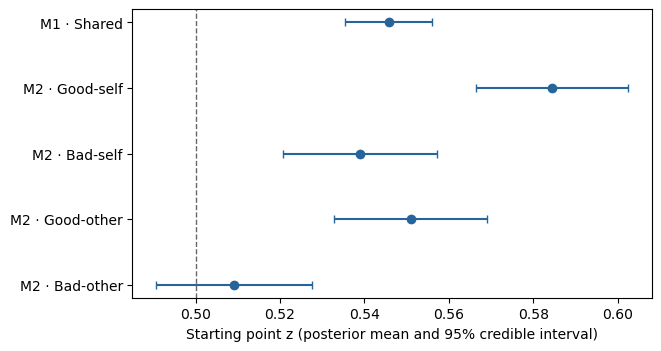

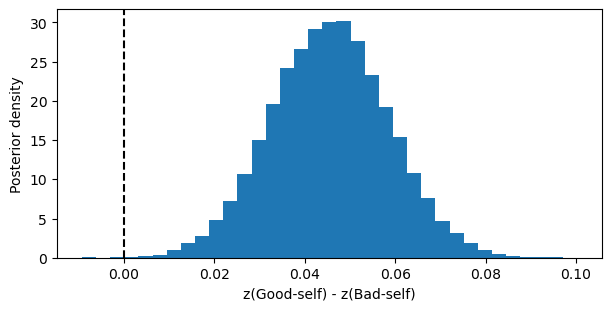

In [8]:
# 生成起点及 Good-self 减 Bad-self 的后验汇总表。
shared_z = group_draws(model_chains["M1"], {"Shared": "z"})
condition_z = group_draws(model_chains["M2"], condition_z_nodes)
condition_z[contrast_name] = condition_z["Good-self"] - condition_z["Bad-self"]

z_summary = pd.concat({
    "M1": summarize_draws(shared_z),
    "M2": summarize_draws(condition_z),
}, names=["model", "estimate"])

# 计算起点相对 0.5 的偏移，以及起点差值大于 0 的概率。
z_summary["reference"] = 0.5
z_summary.loc[("M2", contrast_name), "reference"] = 0.0
z_summary["mean_minus_reference"] = z_summary["mean"] - z_summary["reference"]
z_summary["p_above_reference"] = pd.concat({
    "M1": shared_z.gt(z_summary.loc["M1", "reference"]).mean(),
    "M2": condition_z.gt(z_summary.loc["M2", "reference"]).mean(),
}, names=["model", "estimate"])
display(z_summary.round(3))

# 绘制 M1 共享起点和 M2 四个条件起点的后验均值及可信区间。
z_estimates = z_summary.drop(index=("M2", contrast_name))
positions = np.arange(len(z_estimates))
z_condition_figure, ax = plt.subplots(figsize=(6.5, 3.4), constrained_layout=True)
ax.axvline(0.5, color="0.4", linestyle="--", linewidth=1)
ax.errorbar(
    z_estimates["mean"], positions,
    xerr=[
        z_estimates["mean"] - z_estimates["lower_95"],
        z_estimates["upper_95"] - z_estimates["mean"],
    ],
    fmt="o", color="#27649a", capsize=3,
)
ax.set_yticks(positions, [f"{model} · {estimate}" for model, estimate in z_estimates.index])
ax.invert_yaxis()
ax.set(xlabel="Starting point z (posterior mean and 95% credible interval)")
plt.show()

# 绘制 M2 的 Good-self 减 Bad-self 后验分布。
z_contrast_figure, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.hist(condition_z[contrast_name], bins=35, density=True)
ax.axvline(0, color="black", linestyle="--")
ax.set(xlabel="z(Good-self) - z(Bad-self)", ylabel="Posterior density")
plt.show()

### 5.3 匹配试次的漂移率后验

分别展示 M1 和 M2 在四种形状条件下组层漂移率 \(v\) 的后验密度。

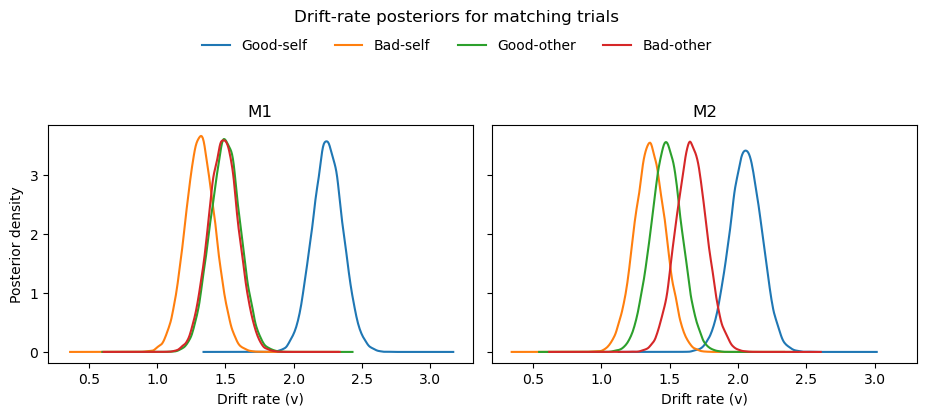

In [9]:
# 绘制匹配试次中四种形状条件的组层漂移率后验密度。
drift_nodes = {
    "Good-self": "v(Self.match.Good)",
    "Bad-self": "v(Self.match.Bad)",
    "Good-other": "v(Other.match.Good)",
    "Bad-other": "v(Other.match.Bad)",
}

drift_figure, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), sharex=True, sharey=True)
for ax, (name, chains) in zip(axes, model_chains.items()):
    drift_draws = group_draws(chains, drift_nodes)
    drift_draws.plot.kde(ax=ax, ind=300, legend=False)
    ax.set(title=name, xlabel="Drift rate (v)", ylabel="")

axes[0].set_ylabel("Posterior density")
drift_figure.suptitle("Drift-rate posteriors for matching trials")
drift_figure.legend(
    *axes[0].get_legend_handles_labels(),
    loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=4, frameon=False,
)
drift_figure.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 6. 留出预测

M1 和 M2 分别从每条实证拟合链抽取 25 次后验参数，各生成 100 份留出模拟。比较各条件的 Match 选择比例，以及按实际选择计算的 RT 第 10、50、90 百分位。

原实验从刺激呈现起的作答窗口约为 0.9–1.2 秒，HDDM 输入排除了超时试次。现有模型拟合和预测使用常规 DDM 的触界时间。解读实测与预测的慢反应尾部时需考虑作答窗口。[时长设置](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Procedure/confirmStudy_proc/Moral_self_asso_exp7_rep_getParams.m#L164-L167) · [作答记录](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Procedure/confirmStudy_proc/Moral_self_asso_exp7_rep_match.m#L243-L268)

In [10]:
# 设置每条链用于留出预测的后验抽样数。
prediction_draws_per_chain = 25


def predict_heldout(data, build_model, chains):
    # 构造留出试次的模型节点，从各拟合链抽取参数样本。
    model = build_model(data)
    observed_nodes = model.get_observeds()["node"]
    draws = pd.concat([
        chain.get_traces().sample(n=prediction_draws_per_chain, random_state=2400 + index)
        for index, chain in enumerate(chains)
    ], ignore_index=True)

    # 按后验抽样模拟整份留出数据，保留条件标签和模拟编号。
    predictions = []
    for draw_index, draw in enumerate(draws.to_dict(orient="records"), start=1):
        model.set_values(draw)
        simulated_groups = []
        for node in observed_nodes:
            simulated = hddm.generate.gen_rts(size=len(node.value), **node.parents.value)
            simulated.index = node.value.index
            simulated_groups.append(simulated)
        simulated_trials = pd.concat(simulated_groups).join(data[trial_columns])
        predictions.append(simulated_trials.assign(draw=draw_index))
    return pd.concat(predictions, ignore_index=True)


# 合并同一批留出试次的实际观测和两套模型的预测。
np.random.seed(2500)
prediction_data = pd.concat({
    "Observed": heldout_trials[[*trial_columns, "response", "rt"]],
    "M1": predict_heldout(heldout_trials, build_m1, model_chains["M1"]),
    "M2": predict_heldout(heldout_trials, build_m2, model_chains["M2"]),
}, names=["source"]).reset_index(level="source")

No model attribute --> setting up standard HDDM
Set model to ddm


No model attribute --> setting up standard HDDM
Set model to ddm


### 6.1 预测误差与区间

合并模拟试次计算平均绝对误差，单位分别为百分点和毫秒。逐份模拟统计选择比例和 RT 分位数，再汇总中位数和 95% 预测区间。

预测区间在 Notebook 中预览第一个试次条件。八种试次条件的完整区间见[留出预测区间表](../outputs/heldout_ppc.csv)。

In [11]:
def choice_and_rt(trials, columns):
    # 计算各组的 Match 选择比例和按实际选择分组的 RT 分位数。
    p_match = trials.groupby(columns)["response"].mean()
    rt = (
        trials.groupby([*columns, "response"])["rt"]
        .quantile([0.1, 0.5, 0.9])
        .mul(1000)
    )
    return p_match, rt.rename_axis(index=[*columns, "response", "quantile"])


# 制作实际观测和两模型的选择比例、RT 分位数表。
choice, rt = choice_and_rt(prediction_data, [*trial_columns, "source"])
choice_check = choice.unstack("source")[["Observed", "M1", "M2"]]
rt_check = rt.unstack("source")[["Observed", "M1", "M2"]]

# 计算各模型相对于观测值的平均绝对误差。
choice_error = choice_check[["M1", "M2"]].sub(choice_check["Observed"], axis="index").abs()
rt_error = rt_check[["M1", "M2"]].sub(rt_check["Observed"], axis="index").abs()
prediction_comparison = pd.DataFrame({
    "choice_mae_percentage_points": 100 * choice_error.mean(skipna=False),
    "rt_quantile_mae_ms": rt_error.mean(skipna=False),
}).rename_axis("model")

# 先显示两模型的预测误差，再列出各条件的选择比例和 RT 分位数。
display(prediction_comparison.round(2))
display(choice_check.round(3))
display(rt_check.round(1))

,choice_mae_percentage_points,rt_quantile_mae_ms
model,,
M1,3.24,87.68
M2,3.34,89.04


source               Observed     M1     M2
match    val  id                           
match    Bad  Other     0.820  0.870  0.874
              Self      0.805  0.846  0.846
         Good Other     0.836  0.869  0.870
              Self      0.888  0.944  0.941
mismatch Bad  Other     0.113  0.117  0.118
              Self      0.171  0.152  0.148
         Good Other     0.188  0.167  0.164
              Self      0.188  0.154  0.155

source                                 Observed      M1      M2
match    val  id    response quantile                          
match    Bad  Other 0.0      0.1          490.6   475.4   458.7
                             0.5          656.7   707.3   680.3
                             0.9          901.7  1165.3  1132.0
                    1.0      0.1          534.8   484.3   493.5
                             0.5          694.2   658.8   665.9
                             0.9          871.5  1055.3  1048.2
              Self  0.0      0.1          511.1   481.8   478.5
                             0.5          691.2   713.8   715.5
                             0.9          877.5  1189.6  1209.2
                    1.0      0.1          560.3   485.8   485.2
                             0.5          734.2   673.9   676.1
                             0.9          893.8  1089.4  1079.7
         Good Other 0.0      0.1          587.7   458.1   456.5
                             0.5          719.5   682.9   684.8
                             0.9          905.8  1161.7  1185.8
                    1.0      0.1          483.6   451.1   450.7
                             0.5          649.8   617.0   616.8
                             0.9          885.7  1014.3  1015.2
              Self  0.0      0.1          423.9   420.3   441.3
                             0.5          660.3   644.6   668.2
                             0.9          832.3  1059.3  1064.6
                    1.0      0.1          504.3   464.2   460.4
                             0.5          632.8   600.5   596.6
                             0.9          814.9   896.2   910.0
mismatch Bad  Other 0.0      0.1          580.1   516.0   509.7
                             0.5          721.8   695.0   690.4
                             0.9          907.1  1038.9  1052.0
                    1.0      0.1          453.8   439.7   450.6
                             0.5          670.1   630.1   658.2
                             0.9          891.8  1007.1  1099.7
              Self  0.0      0.1          585.4   527.9   529.6
                             0.5          726.2   707.4   708.3
                             0.9          905.5  1081.6  1090.9
                    1.0      0.1          524.4   489.6   484.5
                             0.5          739.9   663.8   669.2
                             0.9          976.6  1078.3  1107.6
         Good Other 0.0      0.1          567.4   508.3   513.0
                             0.5          722.1   693.2   695.6
                             0.9          922.8  1087.3  1085.4
                    1.0      0.1          473.3   452.9   446.7
                             0.5          678.5   656.0   653.8
                             0.9          890.0  1087.8  1099.5
              Self  0.0      0.1          584.2   509.0   520.8
                             0.5          715.4   699.7   704.4
                             0.9          906.3  1076.7  1058.4
                    1.0      0.1          503.2   443.0   427.9
                             0.5          646.7   641.7   610.8
                             0.9          849.2  1072.0   997.0

In [12]:
def stack_prediction_statistics(choice, rt):
    # 将选择比例和各 RT 分位数整理到同一张预测检查表。
    rt_by_response = rt.unstack(["response", "quantile"])
    rt_by_response.columns = [
        f"rt_q{q * 100:.0f}_response{int(response)}_ms"
        for response, q in rt_by_response.columns
    ]
    statistics = choice.rename("p_match").to_frame().join(rt_by_response)
    return statistics.rename_axis(columns="statistic").stack()


# 按每份模拟计算统计量，复用上表中的实际观测值。
simulated_predictions = prediction_data[prediction_data["source"].isin(["M1", "M2"])]
draw_choice, draw_rt = choice_and_rt(
    simulated_predictions, ["source", "draw", *trial_columns]
)
simulated_statistics = stack_prediction_statistics(draw_choice, draw_rt)
observed_statistics = stack_prediction_statistics(choice_check["Observed"], rt_check["Observed"]).rename("observed")

# 制作按模型和条件汇总的预测中位数及 95% 预测区间表。
predictive_intervals = (
    simulated_statistics.groupby(level=["source", *trial_columns, "statistic"])
    .agg(
        predicted_median="median",
        predicted_q025=lambda values: values.quantile(0.025),
        predicted_q975=lambda values: values.quantile(0.975),
        n_predictions="count",
    )
    .rename_axis(index=["model", *trial_columns, "statistic"])
    .join(observed_statistics, on=[*trial_columns, "statistic"])
)
predictive_intervals = predictive_intervals[[
    "observed", "predicted_median", "predicted_q025", "predicted_q975", "n_predictions",
]]
display(predictive_intervals.groupby(level="model").head(7).round(3))

observed  predicted_median   
model match val id    statistic                                         
M1    match Bad Other p_match                  0.82             0.870  \
                      rt_q10_response0_ms    490.60           484.326   
                      rt_q10_response1_ms    534.75           485.404   
                      rt_q50_response0_ms    656.70           708.076   
                      rt_q50_response1_ms    694.15           657.701   
                      rt_q90_response0_ms    901.70          1150.282   
                      rt_q90_response1_ms    871.53          1054.158   
M2    match Bad Other p_match                  0.82             0.873   
                      rt_q10_response0_ms    490.60           462.434   
                      rt_q10_response1_ms    534.75           495.007   
                      rt_q50_response0_ms    656.70           681.099   
                      rt_q50_response1_ms    694.15           665.762   
                      rt_q90_response0_ms    901.70          1117.698   
                      rt_q90_response1_ms    871.53          1045.578   

                                           predicted_q025  predicted_q975   
model match val id    statistic                                             
M1    match Bad Other p_match                       0.842           0.897  \
                      rt_q10_response0_ms         424.380         544.092   
                      rt_q10_response1_ms         468.810         500.367   
                      rt_q50_response0_ms         654.710         771.861   
                      rt_q50_response1_ms         642.197         682.139   
                      rt_q90_response0_ms         983.843        1339.935   
                      rt_q90_response1_ms         990.275        1113.549   
M2    match Bad Other p_match                       0.848           0.894   
                      rt_q10_response0_ms         409.471         515.652   
                      rt_q10_response1_ms         476.552         507.155   
                      rt_q50_response0_ms         627.422         751.356   
                      rt_q50_response1_ms         646.585         688.710   
                      rt_q90_response0_ms         929.241        1315.883   
                      rt_q90_response1_ms         995.984        1118.751   

                                           n_predictions  
model match val id    statistic                           
M1    match Bad Other p_match                        100  
                      rt_q10_response0_ms            100  
                      rt_q10_response1_ms            100  
                      rt_q50_response0_ms            100  
                      rt_q50_response1_ms            100  
                      rt_q90_response0_ms            100  
                      rt_q90_response1_ms            100  
M2    match Bad Other p_match                        100  
                      rt_q10_response0_ms            100  
                      rt_q10_response1_ms            100  
                      rt_q50_response0_ms            100  
                      rt_q50_response1_ms            100  
                      rt_q90_response0_ms            100  
                      rt_q90_response1_ms            100

### 6.2 观测与预测的反应时密度

左右两栏分别汇总被试选择 Match 和 Mismatch 时的反应时分布。每栏合并四种形状和两种实际匹配状态。密度按每组的全部试次归一化，使用共同的 50 毫秒区间。横轴画到各组第 99 百分位中的最大值。

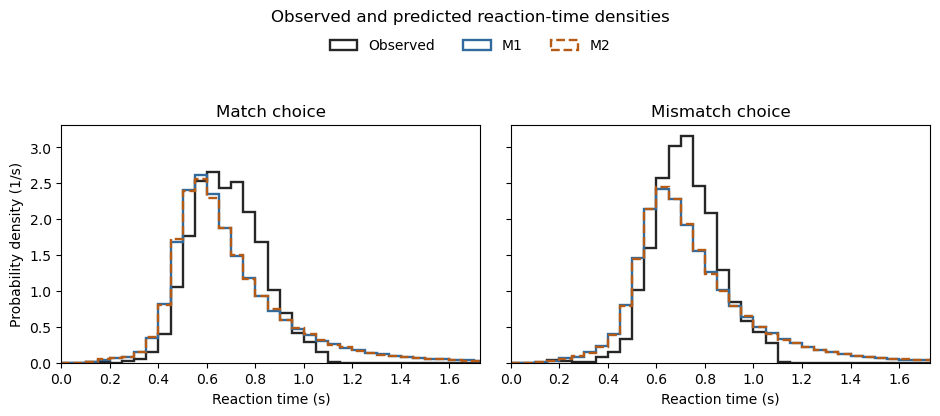

In [13]:
# 绘制留出观测与模型预测的反应时密度，按实际选择分面。
bin_width = 0.05
rt_bins = np.arange(0, prediction_data["rt"].max() + bin_width, bin_width)
rt_limit = prediction_data.groupby(["source", "response"])["rt"].quantile(0.99).max()
styles = {"Observed": ("0.15", "-"), "M1": ("#316a9d", "-"), "M2": ("#b65b15", "--")}

rt_density_figure, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), sharex=True, sharey=True)
for ax, (response, label) in zip(axes, [(1, "Match choice"), (0, "Mismatch choice")]):
    by_choice = prediction_data.loc[prediction_data["response"] == response]
    for source, (color, linestyle) in styles.items():
        rt = by_choice.loc[by_choice["source"] == source, "rt"]
        ax.hist(
            rt, bins=rt_bins, density=True, histtype="step", linewidth=1.7,
            color=color, linestyle=linestyle, label=source,
        )
    ax.set(title=label, xlabel="Reaction time (s)", xlim=(0, rt_limit))

axes[0].set_ylabel("Probability density (1/s)")
rt_density_figure.suptitle("Observed and predicted reaction-time densities")
rt_density_figure.legend(
    *axes[0].get_legend_handles_labels(),
    loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=3, frameon=False,
)
rt_density_figure.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()

## 7. 拟合试次的模型比较

按 Hu et al. (2020) 的 Matching 分析，M1、M2 各用第一条拟合链，在相同的拟合试次上计算 DIC 和后验预测均方误差（PPC-MSE）。每个观测节点对应一名被试的一种试次条件。每个节点从后验抽取 500 次参数，用 HDDM 的 CDF 模拟反应。沿用作者存档表的 `accuracy` 行，将各次模拟的 Match 选择比例与全部拟合试次的观测 Match 比例之差平方后求平均。两项分数均以较低为优。分条件的预测表现见第 6 节。[原作者 Notebook](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Results/3_hddm/HDDM_MS_Rep_match_stim.ipynb) · [原作者预测比较表](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Results/3_hddm/ppc_compare_match_vtz_s.csv)

In [14]:
def fit_comparison_scores(model, observed_match_rate):
    # 计算 DIC，再从该链的保留样本中抽取后验参数。
    dic = model.dic
    np.random.seed(2600)
    retained_draws = len(model.mc.db.trace("deviance")[:])
    squared_errors = []

    # 对每位被试和试次条件模拟 Match 选择比例，计算平方误差。
    for node in model.get_observeds()["node"]:
        parameter_traces = [(parent, parent.trace()) for parent in node.extended_parents]
        for draw in np.random.randint(0, retained_draws, size=500):
            for parent, trace in parameter_traces:
                parent.value = trace[draw]
            rt = hddm.generate.gen_rts(
                size=len(node.value), structured=False, **node.parents.value,
            )
            squared_errors.append((np.mean(rt > 0) - observed_match_rate) ** 2)

    return {"DIC": dic, "PPC_MSE": np.mean(squared_errors)}


# 汇总并显示 M1 与 M2 的 DIC 和后验预测均方误差。
observed_match_rate = training_trials["response"].mean()
fit_model_comparison = pd.DataFrame.from_dict({
    name: fit_comparison_scores(chains[0], observed_match_rate)
    for name, chains in model_chains.items()
}, orient="index").rename_axis("model")
display(fit_model_comparison.round(6))

,DIC,PPC_MSE
model,,
M1,-2821.881908,0.145781
M2,-3040.344912,0.146720


## 8. 保存图表

HDDM 分析表和图分别以 CSV 和 PDF 保存到 `02_reanalysis_2026/outputs`。该目录也包含由 R 绘制的行为图。

In [15]:
# 创建图表的输出目录。
outputs = Path("../outputs")
outputs.mkdir(exist_ok=True)

# 保存模拟恢复、链诊断和起点后验表。
recovery_summary.rename_axis("estimate").to_csv(outputs / "z_recovery.csv")
rhat_table.to_csv(outputs / "rhat.csv")
z_summary.to_csv(outputs / "z_posterior.csv")

# 保存留出试次的预测误差、选择比例、RT 分位数和预测区间表。
prediction_comparison.to_csv(outputs / "heldout_prediction.csv")
choice_check.to_csv(outputs / "heldout_choice_proportions.csv")
rt_check.to_csv(outputs / "heldout_rt_quantiles.csv")
predictive_intervals.to_csv(outputs / "heldout_ppc.csv")

# 保存拟合试次的模型比较表。
fit_model_comparison.to_csv(outputs / "fit_model_comparison.csv")

# 保存四链轨迹图、条件起点图和起点差值图。
trace_figure.savefig(outputs / "trace_diagnostics.pdf")
z_condition_figure.savefig(outputs / "z_by_condition.pdf")
z_contrast_figure.savefig(outputs / "z_self_contrast.pdf")

# 保存匹配试次的漂移率后验和留出反应时密度对照图。
drift_figure.savefig(outputs / "matching_drift_posterior.pdf")
rt_density_figure.savefig(outputs / "heldout_rt_density.pdf")